## Olist customers · data preview

A compact look at the customer dimension: shape, completeness, identifiers, and representative records.

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
from IPython.display import HTML, display

customers_path = Path('/Users/milesreding/olist-warranty-analytics/data/raw/olist_customers_dataset.csv')
customers = pd.read_csv(customers_path)

row_count, column_count = customers.shape
missing_cells = int(customers.isna().sum().sum())
missing_pct = missing_cells / customers.size * 100
unique_customer_ids = customers['customer_unique_id'].nunique()

metric_html = f'''
<style>
.preview-wrap {{
    font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif;
    color: #243447;
    max-width: 1040px;
}}
.preview-kicker {{
    color: #d66b45;
    font-size: 0.76rem;
    font-weight: 700;
    letter-spacing: 0.12em;
    text-transform: uppercase;
    margin: 0 0 0.55rem;
}}
.preview-title {{
    color: #17324d;
    font-size: 1.45rem;
    font-weight: 700;
    margin: 0 0 1rem;
}}
.preview-metrics {{
    display: grid;
    grid-template-columns: repeat(4, minmax(0, 1fr));
    gap: 0.7rem;
    margin: 0 0 1.1rem;
}}
.preview-metric {{
    background: #f4f7f8;
    border: 1px solid #dce6e8;
    border-radius: 8px;
    padding: 0.8rem 0.9rem;
}}
.preview-label {{
    color: #6b7c86;
    font-size: 0.72rem;
    text-transform: uppercase;
    letter-spacing: 0.06em;
}}
.preview-value {{
    color: #17324d;
    font-size: 1.22rem;
    font-weight: 700;
    margin-top: 0.25rem;
}}
@media (max-width: 700px) {{
    .preview-metrics {{ grid-template-columns: repeat(2, minmax(0, 1fr)); }}
}}
</style>
<div class="preview-wrap">
    <p class="preview-kicker">Customer dimension</p>
    <p class="preview-title">Olist customers dataset</p>
    <div class="preview-metrics">
        <div class="preview-metric"><div class="preview-label">Rows</div><div class="preview-value">{row_count:,}</div></div>
        <div class="preview-metric"><div class="preview-label">Columns</div><div class="preview-value">{column_count}</div></div>
        <div class="preview-metric"><div class="preview-label">Unique customers</div><div class="preview-value">{unique_customer_ids:,}</div></div>
        <div class="preview-metric"><div class="preview-label">Missing cells</div><div class="preview-value">{missing_cells:,} ({missing_pct:.1f}%)</div></div>
    </div>
</div>
'''
display(HTML(metric_html))

preview = customers.head(12).copy()
display(
    preview.style
    .set_caption('Representative records · first 12 rows')
    .set_properties(**{
        'font-family': '-apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif',
        'font-size': '0.88rem',
        'text-align': 'left',
        'padding': '8px 10px',
        'border-bottom': '1px solid #e3eaec',
    })
    .set_table_styles([
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'), ('text-align', 'left'), ('color', '#17324d'),
            ('font-weight', '700'), ('font-size', '1rem'), ('padding', '0 0 8px')
        ]},
        {'selector': 'th', 'props': [
            ('background-color', '#17324d'), ('color', 'white'), ('font-weight', '700'),
            ('border', '0'), ('padding', '9px 10px')
        ]},
        {'selector': 'tbody tr:nth-child(even)', 'props': [('background-color', '#f4f7f8')]},
        {'selector': 'tbody tr:hover', 'props': [('background-color', '#fff1e9')]},
    ])
    .hide(axis='index')
)

customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC
fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,sao paulo,SP
5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG
5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR
4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG


In [2]:

geo_path = Path('/Users/milesreding/olist-warranty-analytics/data/raw/olist_geolocation_dataset.csv')
locations = pd.read_csv(geo_path)

row_count, column_count = locations.shape
missing_cells = int(locations.isna().sum().sum())
missing_pct = missing_cells / locations.size * 100
unique_regions = locations['geolocation_zip_code_prefix'].nunique()

metric_html = f'''
<style>
.preview-wrap {{
    font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif;
    color: #243447;
    max-width: 1040px;
}}
.preview-kicker {{
    color: #d66b45;
    font-size: 0.76rem;
    font-weight: 700;
    letter-spacing: 0.12em;
    text-transform: uppercase;
    margin: 0 0 0.55rem;
}}
.preview-title {{
    color: #17324d;
    font-size: 1.45rem;
    font-weight: 700;
    margin: 0 0 1rem;
}}
.preview-metrics {{
    display: grid;
    grid-template-columns: repeat(4, minmax(0, 1fr));
    gap: 0.7rem;
    margin: 0 0 1.1rem;
}}
.preview-metric {{
    background: #f4f7f8;
    border: 1px solid #dce6e8;
    border-radius: 8px;
    padding: 0.8rem 0.9rem;
}}
.preview-label {{
    color: #6b7c86;
    font-size: 0.72rem;
    text-transform: uppercase;
    letter-spacing: 0.06em;
}}
.preview-value {{
    color: #17324d;
    font-size: 1.22rem;
    font-weight: 700;
    margin-top: 0.25rem;
}}
@media (max-width: 700px) {{
    .preview-metrics {{ grid-template-columns: repeat(2, minmax(0, 1fr)); }}
}}
</style>
<div class="preview-wrap">
    <p class="preview-kicker">Locations dimension</p>
    <p class="preview-title">Olist locations dataset</p>
    <div class="preview-metrics">
        <div class="preview-metric"><div class="preview-label">Rows</div><div class="preview-value">{row_count:,}</div></div>
        <div class="preview-metric"><div class="preview-label">Columns</div><div class="preview-value">{column_count}</div></div>
        <div class="preview-metric"><div class="preview-label">Unique regions</div><div class="preview-value">{unique_regions:,}</div></div>
        <div class="preview-metric"><div class="preview-label">Missing cells</div><div class="preview-value">{missing_cells:,} ({missing_pct:.1f}%)</div></div>
    </div>
</div>
'''
display(HTML(metric_html))

preview = locations.head(12).copy()
display(
    preview.style
    .set_caption('Representative records · first 12 rows')
    .set_properties(**{
        'font-family': '-apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif',
        'font-size': '0.88rem',
        'text-align': 'left',
        'padding': '8px 10px',
        'border-bottom': '1px solid #e3eaec',
    })
    .set_table_styles([
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'), ('text-align', 'left'), ('color', '#17324d'),
            ('font-weight', '700'), ('font-size', '1rem'), ('padding', '0 0 8px')
        ]},
        {'selector': 'th', 'props': [
            ('background-color', '#17324d'), ('color', 'white'), ('font-weight', '700'),
            ('border', '0'), ('padding', '9px 10px')
        ]},
        {'selector': 'tbody tr:nth-child(even)', 'props': [('background-color', '#f4f7f8')]},
        {'selector': 'tbody tr:hover', 'props': [('background-color', '#fff1e9')]},
    ])
    .hide(axis='index')
)

geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
1037,-23.545621,-46.639292,sao paulo,SP
1046,-23.546081,-46.644820,sao paulo,SP
1046,-23.546129,-46.642951,sao paulo,SP
1041,-23.544392,-46.639499,sao paulo,SP
1035,-23.541578,-46.641607,sao paulo,SP
1012,-23.547762,-46.635361,são paulo,SP
1047,-23.546273,-46.641225,sao paulo,SP
1013,-23.546923,-46.634264,sao paulo,SP
1029,-23.543769,-46.634278,sao paulo,SP
1011,-23.547640,-46.636032,sao paulo,SP


In [3]:

orders_path = Path('/Users/milesreding/olist-warranty-analytics/data/raw/olist_order_items_dataset.csv')
orders = pd.read_csv(orders_path)

row_count, column_count = orders.shape
missing_cells = int(orders.isna().sum().sum())
missing_pct = missing_cells / orders.size * 100
unique_orders = orders['order_id'].nunique()

metric_html = f'''
<style>
.preview-wrap {{
    font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif;
    color: #243447;
    max-width: 1040px;
}}
.preview-kicker {{
    color: #d66b45;
    font-size: 0.76rem;
    font-weight: 700;
    letter-spacing: 0.12em;
    text-transform: uppercase;
    margin: 0 0 0.55rem;
}}
.preview-title {{
    color: #17324d;
    font-size: 1.45rem;
    font-weight: 700;
    margin: 0 0 1rem;
}}
.preview-metrics {{
    display: grid;
    grid-template-columns: repeat(4, minmax(0, 1fr));
    gap: 0.7rem;
    margin: 0 0 1.1rem;
}}
.preview-metric {{
    background: #f4f7f8;
    border: 1px solid #dce6e8;
    border-radius: 8px;
    padding: 0.8rem 0.9rem;
}}
.preview-label {{
    color: #6b7c86;
    font-size: 0.72rem;
    text-transform: uppercase;
    letter-spacing: 0.06em;
}}
.preview-value {{
    color: #17324d;
    font-size: 1.22rem;
    font-weight: 700;
    margin-top: 0.25rem;
}}
@media (max-width: 700px) {{
    .preview-metrics {{ grid-template-columns: repeat(2, minmax(0, 1fr)); }}
}}
</style>
<div class="preview-wrap">
    <p class="preview-kicker">Orders dimension</p>
    <p class="preview-title">Olist orders dataset</p>
    <div class="preview-metrics">
        <div class="preview-metric"><div class="preview-label">Rows</div><div class="preview-value">{row_count:,}</div></div>
        <div class="preview-metric"><div class="preview-label">Columns</div><div class="preview-value">{column_count}</div></div>
        <div class="preview-metric"><div class="preview-label">Unique orders</div><div class="preview-value">{unique_orders:,}</div></div>
        <div class="preview-metric"><div class="preview-label">Missing cells</div><div class="preview-value">{missing_cells:,} ({missing_pct:.1f}%)</div></div>
    </div>
</div>
'''
display(HTML(metric_html))

preview = orders.head(12).copy()
display(
    preview.style
    .set_caption('Representative records · first 12 rows')
    .set_properties(**{
        'font-family': '-apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif',
        'font-size': '0.88rem',
        'text-align': 'left',
        'padding': '8px 10px',
        'border-bottom': '1px solid #e3eaec',
    })
    .set_table_styles([
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'), ('text-align', 'left'), ('color', '#17324d'),
            ('font-weight', '700'), ('font-size', '1rem'), ('padding', '0 0 8px')
        ]},
        {'selector': 'th', 'props': [
            ('background-color', '#17324d'), ('color', 'white'), ('font-weight', '700'),
            ('border', '0'), ('padding', '9px 10px')
        ]},
        {'selector': 'tbody tr:nth-child(even)', 'props': [('background-color', '#f4f7f8')]},
        {'selector': 'tbody tr:hover', 'props': [('background-color', '#fff1e9')]},
    ])
    .hide(axis='index')
)

order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.900000,13.290000
00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.900000,19.930000
000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.000000,17.870000
00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.990000,12.790000
00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.900000,18.140000
00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.900000,12.690000
00054e8431b9d7675808bcb819fb4a32,1,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.900000,11.850000
000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.000000,70.750000
0005a1a1728c9d785b8e2b08b904576c,1,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.950000,11.650000
0005f50442cb953dcd1d21e1fb923495,1,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.990000,11.400000


In [4]:

products_path = Path('/Users/milesreding/olist-warranty-analytics/data/raw/olist_products_dataset.csv')
products = pd.read_csv(products_path)

row_count, column_count = products.shape
missing_cells = int(products.isna().sum().sum())
missing_pct = missing_cells / products.size * 100
unique_products = products['product_id'].nunique()
unique_categories = products['product_category_name'].nunique()

metric_html = f'''
<style>
.preview-wrap {{
    font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif;
    color: #243447;
    max-width: 1040px;
}}
.preview-kicker {{
    color: #d66b45;
    font-size: 0.76rem;
    font-weight: 700;
    letter-spacing: 0.12em;
    text-transform: uppercase;
    margin: 0 0 0.55rem;
}}
.preview-title {{
    color: #17324d;
    font-size: 1.45rem;
    font-weight: 700;
    margin: 0 0 1rem;
}}
.preview-metrics {{
    display: grid;
    grid-template-columns: repeat(4, minmax(0, 1fr));
    gap: 0.7rem;
    margin: 0 0 1.1rem;
}}
.preview-metric {{
    background: #f4f7f8;
    border: 1px solid #dce6e8;
    border-radius: 8px;
    padding: 0.8rem 0.9rem;
}}
.preview-label {{
    color: #6b7c86;
    font-size: 0.72rem;
    text-transform: uppercase;
    letter-spacing: 0.06em;
}}
.preview-value {{
    color: #17324d;
    font-size: 1.22rem;
    font-weight: 700;
    margin-top: 0.25rem;
}}
@media (max-width: 700px) {{
    .preview-metrics {{ grid-template-columns: repeat(2, minmax(0, 1fr)); }}
}}
</style>
<div class="preview-wrap">
    <p class="preview-kicker">Products dimension</p>
    <p class="preview-title">Olist products dataset</p>
    <div class="preview-metrics">
        <div class="preview-metric"><div class="preview-label">Rows</div><div class="preview-value">{row_count:,}</div></div>
        <div class="preview-metric"><div class="preview-label">Columns</div><div class="preview-value">{column_count}</div></div>
        <div class="preview-metric"><div class="preview-label">Unique products</div><div class="preview-value">{unique_products:,}</div></div>
        <div class="preview-metric"><div class="preview-label">Unique categories</div><div class="preview-value">{unique_categories:,}</div></div>
        <div class="preview-metric"><div class="preview-label">Missing cells</div><div class="preview-value">{missing_cells:,} ({missing_pct:.1f}%)</div></div>
    </div>
</div>
'''
display(HTML(metric_html))

preview = products.head(12).copy()
display(
    preview.style
    .set_caption('Representative records · first 12 rows')
    .set_properties(**{
        'font-family': '-apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif',
        'font-size': '0.88rem',
        'text-align': 'left',
        'padding': '8px 10px',
        'border-bottom': '1px solid #e3eaec',
    })
    .set_table_styles([
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'), ('text-align', 'left'), ('color', '#17324d'),
            ('font-weight', '700'), ('font-size', '1rem'), ('padding', '0 0 8px')
        ]},
        {'selector': 'th', 'props': [
            ('background-color', '#17324d'), ('color', 'white'), ('font-weight', '700'),
            ('border', '0'), ('padding', '9px 10px')
        ]},
        {'selector': 'tbody tr:nth-child(even)', 'props': [('background-color', '#f4f7f8')]},
        {'selector': 'tbody tr:hover', 'props': [('background-color', '#fff1e9')]},
    ])
    .hide(axis='index')
)

product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.000000,287.000000,1.000000,225.000000,16.000000,10.000000,14.000000
3aa071139cb16b67ca9e5dea641aaa2f,artes,44.000000,276.000000,1.000000,1000.000000,30.000000,18.000000,20.000000
96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.000000,250.000000,1.000000,154.000000,18.000000,9.000000,15.000000
cef67bcfe19066a932b7673e239eb23d,bebes,27.000000,261.000000,1.000000,371.000000,26.000000,4.000000,26.000000
9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.000000,402.000000,4.000000,625.000000,20.000000,17.000000,13.000000
41d3672d4792049fa1779bb35283ed13,instrumentos_musicais,60.000000,745.000000,1.000000,200.000000,38.000000,5.000000,11.000000
732bd381ad09e530fe0a5f457d81becb,cool_stuff,56.000000,1272.000000,4.000000,18350.000000,70.000000,24.000000,44.000000
2548af3e6e77a690cf3eb6368e9ab61e,moveis_decoracao,56.000000,184.000000,2.000000,900.000000,40.000000,8.000000,40.000000
37cc742be07708b53a98702e77a21a02,eletrodomesticos,57.000000,163.000000,1.000000,400.000000,27.000000,13.000000,17.000000
8c92109888e8cdf9d66dc7e463025574,brinquedos,36.000000,1156.000000,1.000000,600.000000,17.000000,10.000000,12.000000


Minimum price: $0.85
Maximum price: $6,735.00


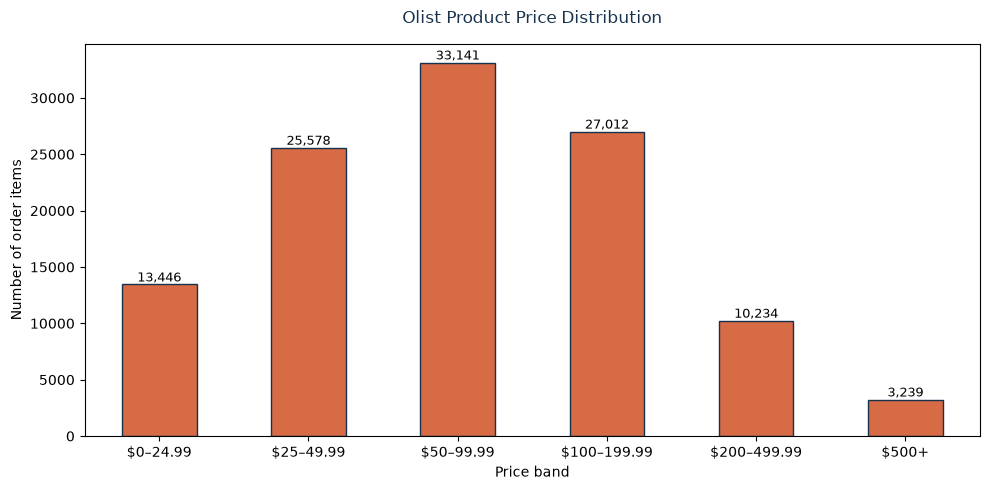

In [5]:
import matplotlib.pyplot as plt

price_data = pd.to_numeric(orders['price'], errors='coerce').dropna()

min_price = price_data.min()
max_price = price_data.max()

print(f"Minimum price: ${min_price:,.2f}")
print(f"Maximum price: ${max_price:,.2f}")

price_bins = [0, 25, 50, 100, 200, 500, float('inf')]
price_labels = ['$0–24.99', '$25–49.99', '$50–99.99', '$100–199.99', '$200–499.99', '$500+']

price_distribution = pd.cut(
    price_data,
    bins=price_bins,
    labels=price_labels,
    right=False
).value_counts().sort_index()

ax = price_distribution.plot(
    kind='bar',
    figsize=(10, 5),
    color='#d66b45',
    edgecolor='#17324d'
)

ax.set_title('Olist Product Price Distribution', color='#17324d', pad=15)
ax.set_xlabel('Price band')
ax.set_ylabel('Number of order items')
ax.tick_params(axis='x', rotation=0)

for index, value in enumerate(price_distribution):
    ax.text(index, value, f'{value:,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [7]:
db_path = Path('/Users/milesreding/olist-warranty-analytics/data/processed/olist.duckdb')
db_path.parent.mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(db_path))
con.sql("SHOW TABLES").df()

,name
0,agg_items
1,agg_payments
2,agg_reviews
3,dim_geo
4,dim_products
5,fact_order_items
6,fact_orders
7,map_category
8,raw_category_translation
9,raw_customers


In [8]:
tables = con.sql("SHOW TABLES").df()['name']

for t in tables:
    n = con.sql(f"SELECT COUNT(*) AS n FROM {t}").fetchone()[0]
    print(f"{t:<28} {n:>8,} rows")

agg_items                      98,666 rows
agg_payments                   99,440 rows
agg_reviews                    98,673 rows
dim_geo                        19,015 rows
dim_products                   32,951 rows
fact_order_items              112,650 rows
fact_orders                    99,441 rows
map_category                       71 rows
raw_category_translation           71 rows
raw_customers                  99,441 rows
raw_geolocation              1,000,163 rows
raw_order_items               112,650 rows
raw_order_payments            103,886 rows
raw_order_reviews              99,224 rows
raw_orders                     99,441 rows
raw_products                   32,951 rows
raw_sellers                     3,095 rows


In [9]:
con.sql("SELECT * FROM fact_orders LIMIT 10").df()

,order_id,order_status,customer_unique_id,customer_state,customer_zip_code_prefix,seller_state,seller_zip_code_prefix,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,...,sell_lng,transit_days,approval_lag_days,carrier_lag_days,days_late,promise_window_days,is_late,same_state,ship_distance_km,in_window
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,7c396fd4830fd04220f754e42b4e5bff,SP,03149,SP,09350,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,...,-46.444238,8,0.041667,2,-8,16,False,True,18.576110,True
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,af07308b275d755c9edb36a90c618231,BA,47813,SP,31570,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,...,-43.980427,14,1.291667,0,-6,20,False,False,851.495069,True
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,3a653a41f6f9fc3d2a113cf8398680e8,GO,75265,SP,14840,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,...,-48.229601,9,0.000000,0,-18,27,False,False,514.410666,True
3,ad21c59c0840e6cb83a9ceb5573f8159,delivered,72632f0f9dd73dfee390c9b22eb56dd6,SP,09195,SP,08752,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,...,-46.262086,3,0.041667,1,-10,13,False,True,29.676625,True
4,a4591c265e18cb1dcee52889e2d8acc3,delivered,80bb27c7c16e8f973207a5086ab329e2,PR,86320,SP,07112,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,...,-46.516142,17,0.041667,2,-6,23,False,False,411.394362,True
5,136cce7faa42fdb2cefd53fdc79a6098,invoiced,36edbb3fb164b1f16485364b6fb04c73,RS,98900,SP,05455,2017-04-11 12:22:08,2017-04-13 13:25:17,NaT,...,-46.711854,<NA>,2.041667,<NA>,<NA>,28,<NA>,False,913.640074,True
6,6514b8ad8028c9f2cc2374ded245783f,delivered,932afa1e708222e5821dac9cd5db4cae,RJ,26525,SP,12940,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,...,-46.552881,10,0.000000,6,-12,22,False,False,322.277082,True
7,76c6e866289321a7c93b82b54852dc33,delivered,39382392765b6dc74812866ee5ee92a7,RS,99655,SP,13720,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,...,-46.947759,10,1.333333,1,-32,42,False,False,869.946044,True
8,e69bfb5eb88e0ed6a785585b27e16dbf,delivered,299905e3934e9e181bfb2e164dd4b4f8,SP,18075,SP,08577,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,...,-46.366721,18,0.041667,12,-7,25,False,True,112.263374,True
9,e6ce16cb79ec1d90b1da9085a6118aeb,delivered,f2a85dec752b8517b5e58a06ff3cd937,RJ,20780,ES,29156,2017-05-16 19:41:10,2017-05-16 19:50:18,2017-05-18 11:40:40,...,-40.411675,13,0.000000,2,-9,22,False,False,414.959288,True


In [10]:
con.sql("DESCRIBE fact_orders").df()

,column_name,column_type,null,key,default,extra
0,order_id,VARCHAR,YES,None,None,None
1,order_status,VARCHAR,YES,None,None,None
2,customer_unique_id,VARCHAR,YES,None,None,None
3,customer_state,VARCHAR,YES,None,None,None
4,customer_zip_code_prefix,VARCHAR,YES,None,None,None
5,seller_state,VARCHAR,YES,None,None,None
6,seller_zip_code_prefix,VARCHAR,YES,None,None,None
7,order_purchase_timestamp,TIMESTAMP,YES,None,None,None
8,order_approved_at,TIMESTAMP,YES,None,None,None
9,order_delivered_carrier_date,TIMESTAMP,YES,None,None,None


In [11]:
con.sql("SELECT * FROM agg_items LIMIT 10").df()

,order_id,n_items,n_distinct_products,n_sellers,items_total,freight_total,order_value,max_item_price,primary_seller_id,primary_product_id
0,0028de0ca693a1bb26448916a81105cc,1,1,1,29.99,15.31,45.30,29.99,955fee9216a65b617aa5c0531780ce60,059344baebbeaa42fa9f2bbe11b1583e
1,00611822267e76e0055c25c18506f06e,1,1,1,159.90,20.31,180.21,159.90,23d7c96d4a1160db1c726b248601b25a,3d514fecadf6cef40a2a32a3c20cd1c8
2,0068e836900867da359bd81db9227a33,1,1,1,96.99,16.44,113.43,96.99,5b67882648febfb6e1225e6ad7164f6b,735413ccfa564132a231aad945ef85ad
3,006dd93155bc2abd844cc5eed3a0fe7f,1,1,1,49.90,7.78,57.68,49.90,cab85505710c7cb9b720bceb52b01cee,1ec486885049bbb9b79351d150ed18c4
4,007bbb40c95870c0f75a7855f2636c65,1,1,1,148.90,13.95,162.85,148.90,1e8b33f18b4f7598d87f5cbee2282cc2,0ec7b6a863e219792bc4d50d3a62a839
5,0081ab2c99dc85945c28926b77dc6960,1,1,1,269.00,10.70,279.70,269.00,96493fab2fbb13a14d0c0e8772eef5c3,e1c0a39b7f806727ea5121c60035ed3c
6,009742b43f4530bc3db7f62332c50f4b,1,1,1,133.74,12.44,146.18,133.74,17e34d8224d27a541263c4c64b11a56b,ee3e94e918d05a5da04a4cb547e91dcc
7,009fa9bd0d92710e840793bfefa80867,1,1,1,84.99,15.34,100.33,84.99,cc419e0650a3c5ba77189a1882b7556a,617186c3d97ea56c9c683a8a3974e8c1
8,00ab9fa91aafa3d881164b0da48999aa,1,1,1,579.00,65.34,644.34,579.00,ceaec5548eefc6e23e6607c5435102e7,224037b21bfa8621e39c265513ee6594
9,00b402e8a76d3da83714c52d3977cc2d,1,1,1,139.65,26.26,165.91,139.65,edb1ef5e36e0c8cd84eb3c9b003e486d,72d6074ef5c81ec3102b3f2a052c5f49


In [12]:
con.sql("SELECT * FROM dim_products LIMIT 10").df()

,product_id,category_pt,category_english,category_l1,warranty_eligible,product_name_length,product_description_length,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_volume_cm3
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery,health_beauty,False,40,287,1,225,16,10,14,2240
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art,home_goods,False,44,276,1,1000,30,18,20,10800
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure,musical_leisure,True,46,250,1,154,18,9,15,2430
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby,baby_kids,False,27,261,1,371,26,4,26,2704
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares,home_goods,False,37,402,4,625,20,17,13,4420
5,41d3672d4792049fa1779bb35283ed13,instrumentos_musicais,musical_instruments,musical_leisure,True,60,745,1,200,38,5,11,2090
6,732bd381ad09e530fe0a5f457d81becb,cool_stuff,cool_stuff,home_goods,False,56,1272,4,18350,70,24,44,73920
7,2548af3e6e77a690cf3eb6368e9ab61e,moveis_decoracao,furniture_decor,furniture,True,56,184,2,900,40,8,40,12800
8,37cc742be07708b53a98702e77a21a02,eletrodomesticos,home_appliances,appliances,True,57,163,1,400,27,13,17,5967
9,8c92109888e8cdf9d66dc7e463025574,brinquedos,toys,baby_kids,False,36,1156,1,600,17,10,12,2040


In [15]:
product_warranty_counts = con.sql("""
    SELECT
        category_l1,
        CASE
            WHEN warranty_eligible THEN 'Warrantable'
            ELSE 'Not warrantable'
        END AS warranty_status,
        COUNT(DISTINCT product_id) AS product_count
    FROM dim_products
    GROUP BY category_l1, warranty_status
    ORDER BY category_l1, warranty_status
""").df()

display(product_warranty_counts)

,category_l1,warranty_status,product_count
0,appliances,Warrantable,846
1,auto,Warrantable,1900
2,baby_kids,Not warrantable,2330
3,electronics,Warrantable,3848
4,fashion,Not warrantable,2899
5,food_pet,Not warrantable,986
6,furniture,Warrantable,3387
7,health_beauty,Not warrantable,3324
8,home_goods,Not warrantable,6342
9,media_stationery,Not warrantable,1295
